In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.decomposition import PCA, FastICA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import numpy as np
from scipy.cluster.hierarchy import dendrogram, linkage, leaves_list

In [15]:
v3_prolific = pd.read_csv("outputs/v3_prolific/all_cognitive_results_v3_prolific.csv")
v3_prolific['study'] = "v3_prolific"
v2_prolific = pd.read_csv("outputs/v2_prolific/all_cognitive_results_v2_prolific.csv")
v2_prolific['study'] = "v2_prolific"
v1_prolific = pd.read_csv("outputs/v1_prolific/all_cognitive_results_v1_prolific.csv")
v1_prolific['study'] = "v1_prolific"
v0_prolific = pd.read_csv("outputs/v0_prolific/all_cognitive_results_v0_prolific.csv")
v0_prolific['study'] = "v0_prolific"
v3_utl = pd.read_csv("outputs/v3_utl/all_cognitive_results_v3_utl.csv")
v3_utl['study'] = "v3_utl"
v1_ubx = pd.read_csv("outputs/v1_ubx/all_cognitive_results_v1_ubx.csv")
v1_ubx['study'] = "v1_ubx"
v0_ubx = pd.read_csv("outputs/v0_ubx/all_cognitive_results_v0_ubx.csv")
v0_ubx['study'] = "v0_ubx"
df = pd.concat([v3_prolific, v2_prolific, v1_prolific, v3_utl, v1_ubx, v0_ubx], ignore_index=True)

In [16]:
# Display the PCA:
def get_scatter_of_indiv_2D(df_pca):
    # Create a scatter plot of the first two principal components
    plt.figure(figsize=(8, 6))
    plt.scatter(df_pca['PC1'], df_pca['PC2'], marker='o', c='b', alpha=0.7)
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.title('PCA - Scatter Plot of Principal Components 1 and 2')
    plt.grid()
    # Show or save the plot
    plt.show()

def create_correlation_circle(variable_contributions, variable_names):
    # Create a figure
    fig, ax = plt.subplots(figsize=(8, 8))
    # Define a colormap for arrows
    cmap = plt.get_cmap('tab10')
    # Plot the correlation circle (arrows) with unique colors and labels
    for i, var_name in enumerate(variable_names):
        arrow_length = np.sqrt(variable_contributions[i, 0] ** 2 + variable_contributions[i, 1] ** 2)
        arrow_x = variable_contributions[i, 0] / arrow_length
        arrow_y = variable_contributions[i, 1] / arrow_length
        color = cmap(i % 10)  # Use modulo to cycle through colors
        plt.arrow(0, 0, arrow_x, arrow_y, color=color, alpha=0.7, label=var_name)
    # Add a circle of radius 1
    circle = plt.Circle((0, 0), 1, fill=False, color='black', linestyle='dotted', alpha=0.5)
    ax.add_artist(circle)
    # Add a legend on the right of the plot
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid()
    plt.axhline(0, color='black', lw=0.5)
    plt.axvline(0, color='black', lw=0.5)
    # Set axis limits to show the circle
    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-1.5, 1.5)
    # Show or save the plot
    plt.show()  # Use plt.savefig("filename.png") to save the plot to a file
    
def get_heat_and_dendro(variable_contributions, variable_names):    
    # Assuming you have variable_contributions, a 2D numpy array with the variable contributions to components
    # Also, make sure you have the original variable names in a list, e.g., variable_names
    # Keep only the first 10 components
    variable_contributions = variable_contributions[:, :10]
    # Create a linkage matrix for hierarchical clustering
    linkage_matrix = linkage(variable_contributions, method='ward')
    # Perform hierarchical clustering and get the reordered indices
    order = leaves_list(linkage_matrix)
    # Reorder the variable names based on clustering
    ordered_variable_names = [variable_names[i] for i in order]
    # Create a larger figure for the heatmap
    fig, ax1 = plt.subplots(figsize=(12, 8))
    # Create a heatmap of the reordered variable contributions with a custom colormap
    cmap = LinearSegmentedColormap.from_list("custom_colormap", [(0, 'blue'), (0.5, 'white'), (1, 'red')])
    cax = ax1.matshow(variable_contributions[order, :], cmap=cmap, aspect='auto', vmin=-1, vmax=1, extent=(-0.5, 10 - 0.5, len(variable_names) - 0.5, -0.5))
    # Invert the y-axis to match the dendrogram
    ax1.invert_yaxis()
    ax1.set_yticks(np.arange(len(ordered_variable_names)))
    ax1.set_yticklabels(ordered_variable_names)
    ax1.set_xticks(np.arange(10))
    ax1.set_xticklabels([f'PC{i + 1}' for i in range(10)], rotation=0)
    # Add text labels with values in black
    for i in range(len(variable_names)):
        for j in range(10):
            value = variable_contributions[order, :][i, j]
            ax1.text(j, i, f'{value:.2f}', ha='center', va='center', color='black', fontsize=10, fontweight='bold')
    # Add a color bar for reference
    cbar = fig.colorbar(cax, ax=ax1, ticks=[-1, 0, 1])
    cbar.set_label('Loading')
    plt.title('Variable Loadings for Principal Components (First 10 Components) - Heatmap')
    # Create a separate figure for the dendrogram
    fig, ax2 = plt.subplots(figsize=(3, 8))
    # Create a dendrogram for hierarchical clustering with custom labels
    dendrogram(linkage_matrix, ax=ax2, orientation='left', color_threshold=0.5 * np.max(linkage_matrix[:, 2]))
    ax2.set_yticklabels(ordered_variable_names)
    plt.title('Hierarchical Clustering Dendrogram')
    plt.show()    
    
def get_scree_plot(pca_object, n_components):
    # Generate Scree Plot
    n_components_kaiser = sum(pca_object.explained_variance_ > 1)
    variance_explained_kaiser = sum(pca_object.explained_variance_ratio_[:n_components_kaiser]) * 100
    plt.figure(figsize=(10, 6))
    # Create bar plot for explained variance
    plt.bar(range(1, n_components + 1), pca_object.explained_variance_ratio_, alpha=0.7, color='blue', label='Variance Explained by Each PC')
    # Add line plot on top of the bar plot
    plt.plot(range(1, n_components + 1), pca_object.explained_variance_ratio_, marker='o', linestyle='--', color='red', label='Cumulative Variance Explained')
    # Add a vertical line for the Kaiser Criterion
    plt.vlines(x=n_components_kaiser, ymin=0, ymax=1.1*pca_object.explained_variance_ratio_[0], colors='green', linestyles='dashed', label='Kaiser Criterion')
    plt.title(f'Scree Plot - \n Variance explained by kept components: {variance_explained_kaiser:.2f} ')
    plt.xlabel('Principal Component')
    plt.ylabel('Variance Explained')
    plt.legend()
    plt.show()

In [19]:
def fill_na_with_mean(data, columns_for_pca):
    for study in data['study'].unique():
        study_mean = data.loc[data['study'] == study, columns_for_pca].mean()
        data.loc[data['study'] == study, columns_for_pca] = data.loc[data['study'] == study, columns_for_pca].fillna(study_mean)
    return data
    
def normalize_data(data, columns_for_pca):
    # Create a StandardScaler instance
    scaler = StandardScaler()
    # Fit the scaler on the selected columns and transform the data
    df_normalized = scaler.fit_transform(data[columns_for_pca])
    # Create a new DataFrame with the scaled data
    df_normalized = pd.DataFrame(df_normalized, columns=columns_for_pca)
    return df_normalized

# Assuming you have df_normalized, the DataFrame with centered and scaled data
def get_DR(DR_algo, df_normalized, columns_for_pca, n_components):
    # Fit the PCA model to the data
    DR_algo.fit(df_normalized)
    # Transform the data to the principal components
    df_pca = DR_algo.transform(df_normalized)
    # Create a new DataFrame with the principal components
    df_pca = pd.DataFrame(data=df_pca, columns=[f'PC{i + 1}' for i in range(n_components)])
    # Assuming you have df_normalized, the DataFrame with the centered and scaled data,
    # and a list of variable names
    # Calculate the variable contributions (correlations with principal components)
    variable_contributions = np.corrcoef(df_normalized.T, df_pca.T)[:len(columns_for_pca), -n_components:]
    return df_pca, variable_contributions, DR_algo


def run_dimensionality_reduction(data, columns_for_pca, DR_type='PCA'):
    filled_data = fill_na_with_mean(data, columns_for_pca)
    df_normalized = normalize_data(filled_data, columns_for_pca)
    # Choose the dim reduction algo:
    # Create a PCA instance with the number of components you want to retain
    n_components = len(df_normalized.columns)  # You can adjust this number as needed
    if DR_type == "PCA":
        model = PCA(n_components=n_components)
    elif DR_type == "ICA":
         model = FastICA(n_components=n_components,random_state=0, whiten='unit-variance')
    df_pca, variable_contributions, model = get_DR(model, df_normalized, columns_for_pca, n_components)
    get_scatter_of_indiv_2D(df_pca)
    if DR_type == "PCA":
        get_scree_plot(model, n_components)
    create_correlation_circle(variable_contributions, columns_for_pca)
    get_heat_and_dendro(variable_contributions, columns_for_pca)

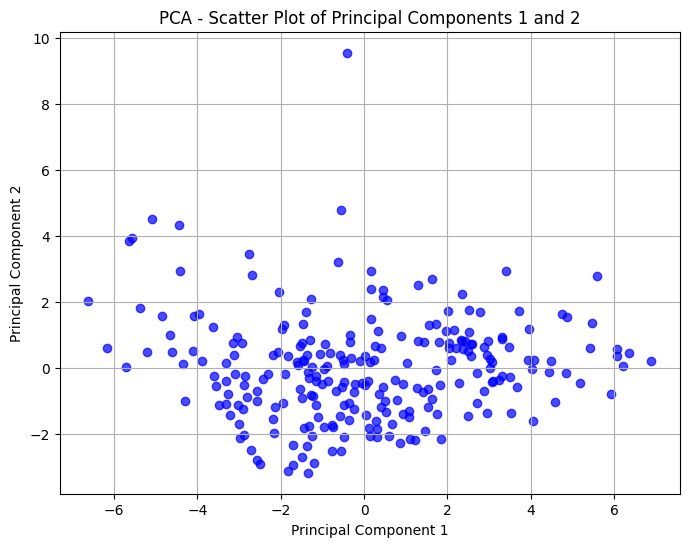

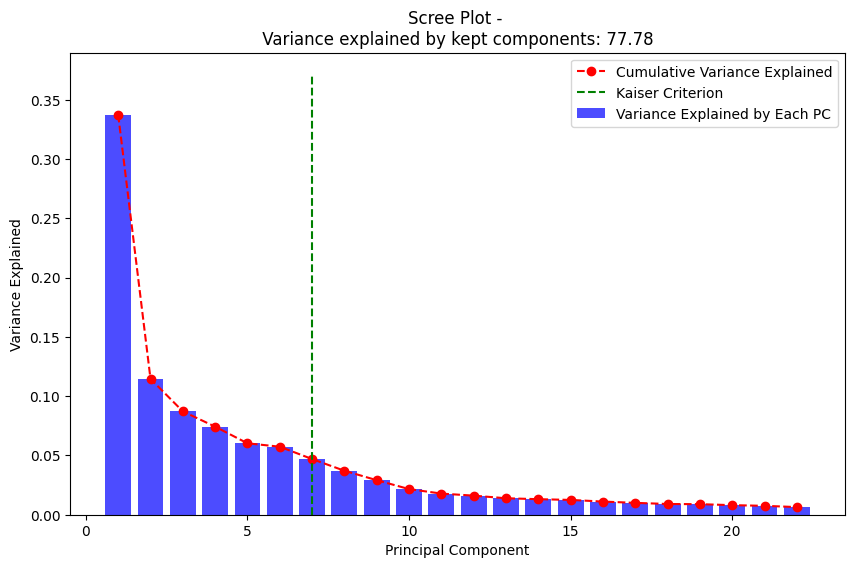

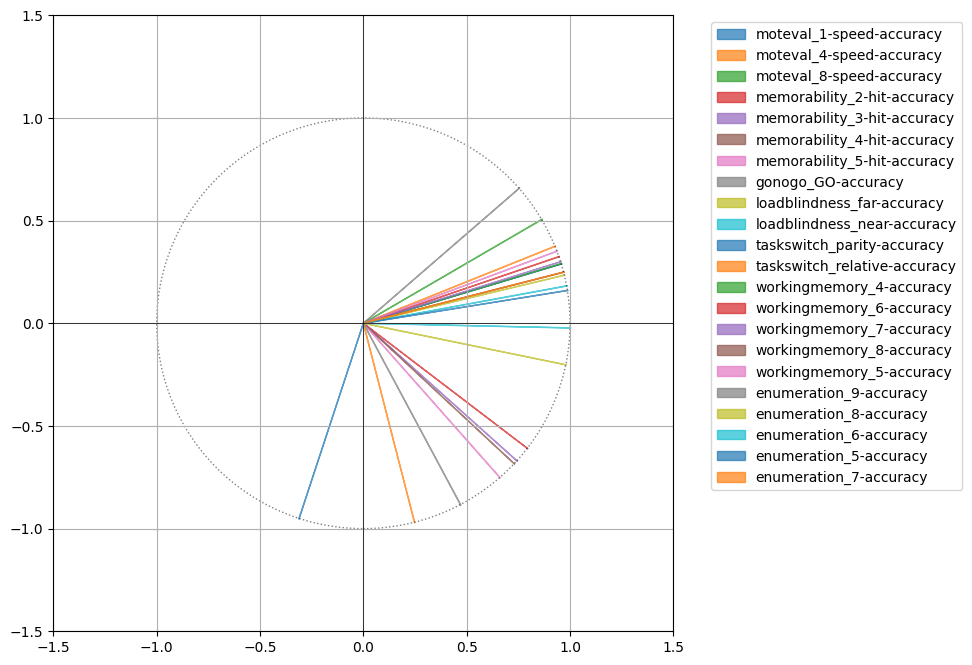

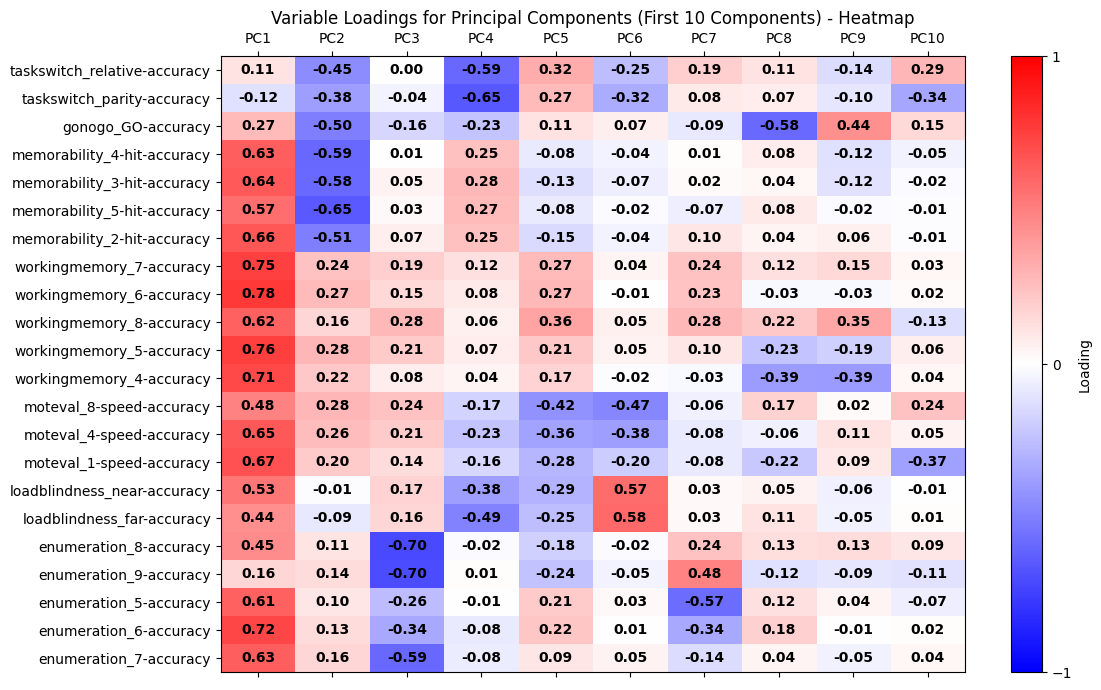

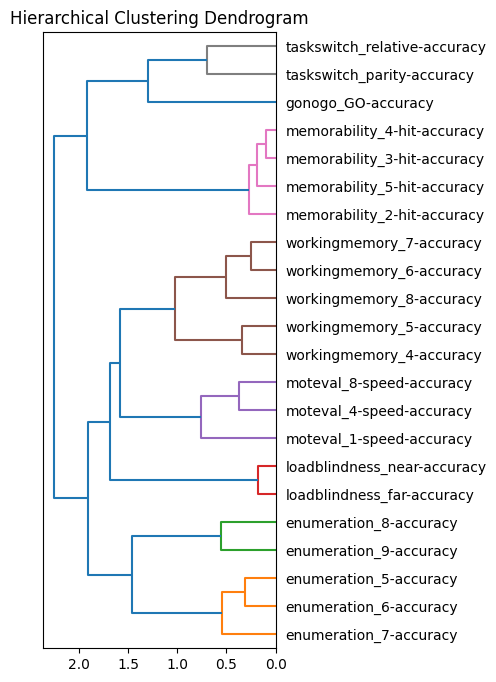

/Users/m.adolphe/.local/share/virtualenvs/results_analysis-lNYwU5Fl/lib/python3.10/site-packages/sklearn/decomposition/_fastica.py:123: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum number of iterations.
  warnings.warn(


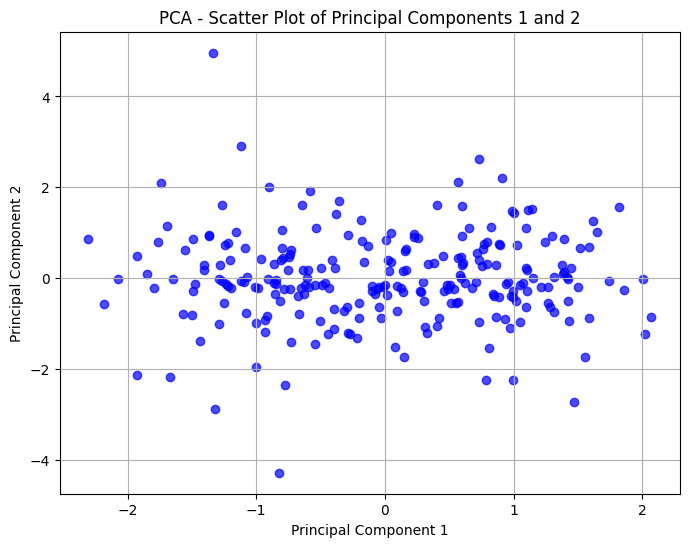

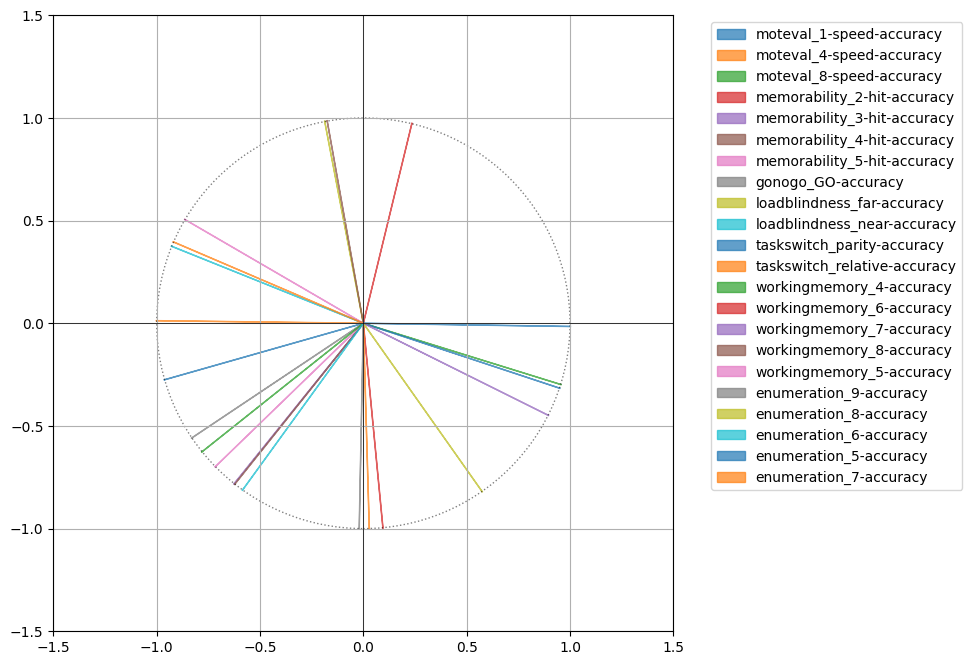

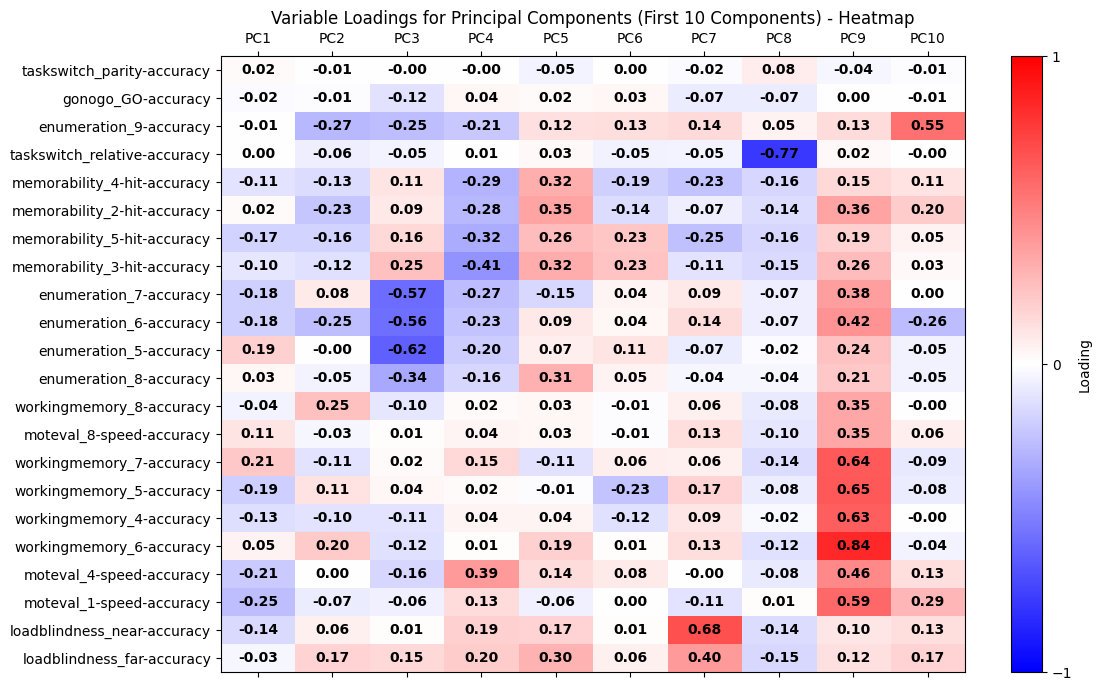

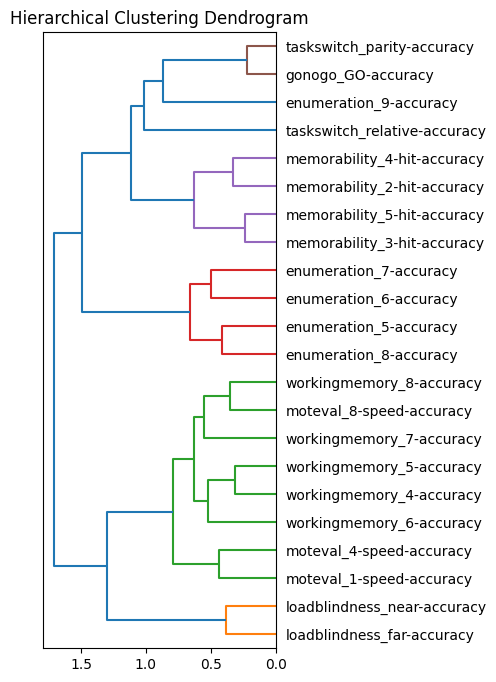

In [20]:
# Get a list of columns with at least one NaN value and the count of NaN values in each column
values_to_keep = ["v3_prolific", "v3_utl"]
# Filter the DataFrame to keep only rows with "study" values in the list
df_v3 = df[df['study'].isin(values_to_keep)]
# Kept columns:
moteval = ["moteval_1-speed-accuracy", "moteval_4-speed-accuracy", "moteval_8-speed-accuracy"]
enumeration = ['enumeration_9-accuracy','enumeration_8-accuracy','enumeration_6-accuracy','enumeration_5-accuracy','enumeration_7-accuracy']
loadblindness = ['loadblindness_far-accuracy', 'loadblindness_near-accuracy']
gonogo = ["gonogo_GO-accuracy"]
workingmemory = ['workingmemory_4-accuracy','workingmemory_6-accuracy','workingmemory_7-accuracy','workingmemory_8-accuracy','workingmemory_5-accuracy']
memorability = ['memorability_2-hit-accuracy', 'memorability_3-hit-accuracy', 'memorability_4-hit-accuracy', 'memorability_5-hit-accuracy']
taskswitch = ['taskswitch_parity-accuracy','taskswitch_relative-accuracy']
kept_columns = ["participant_id","condition","task_status","study"]
tasks =  moteval + memorability + gonogo + loadblindness + taskswitch + workingmemory + enumeration
# With all data:
df_v3 = df_v3[kept_columns+tasks]
run_dimensionality_reduction(df_v3, tasks, DR_type='PCA')
run_dimensionality_reduction(df_v3, tasks, DR_type='ICA')

In [ ]:
# With all data:
df_v3 = df_v3[kept_columns+tasks]
df_v3_pre = df_v3[df_v3['task_status']=="PRE_TEST"]
#run_PCA(df_v3, tasks)

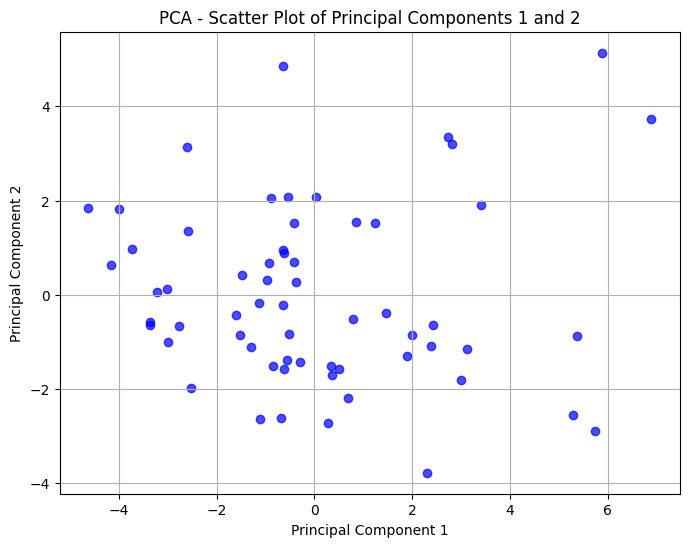

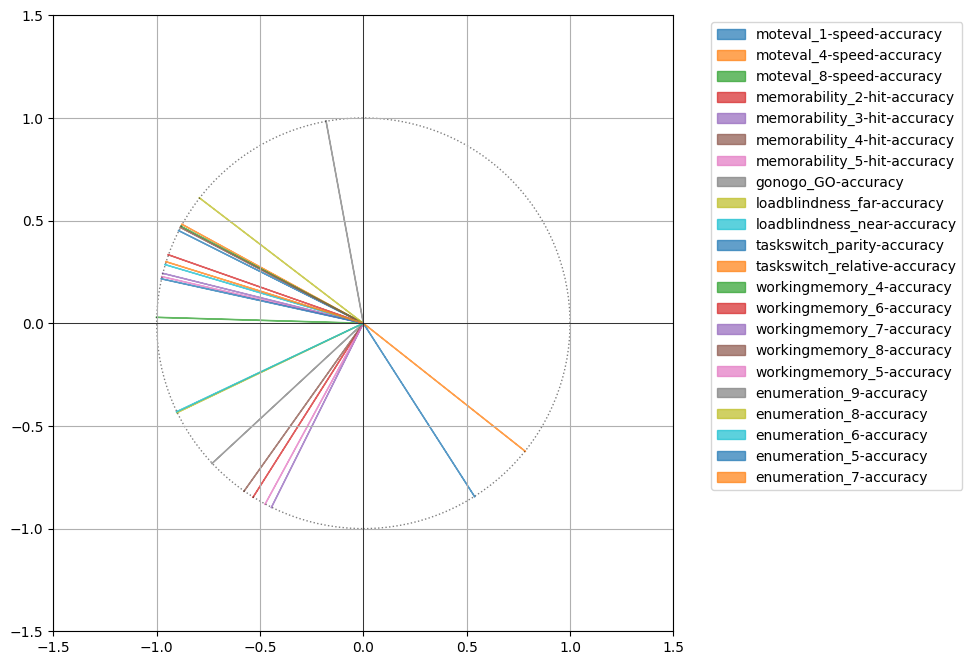

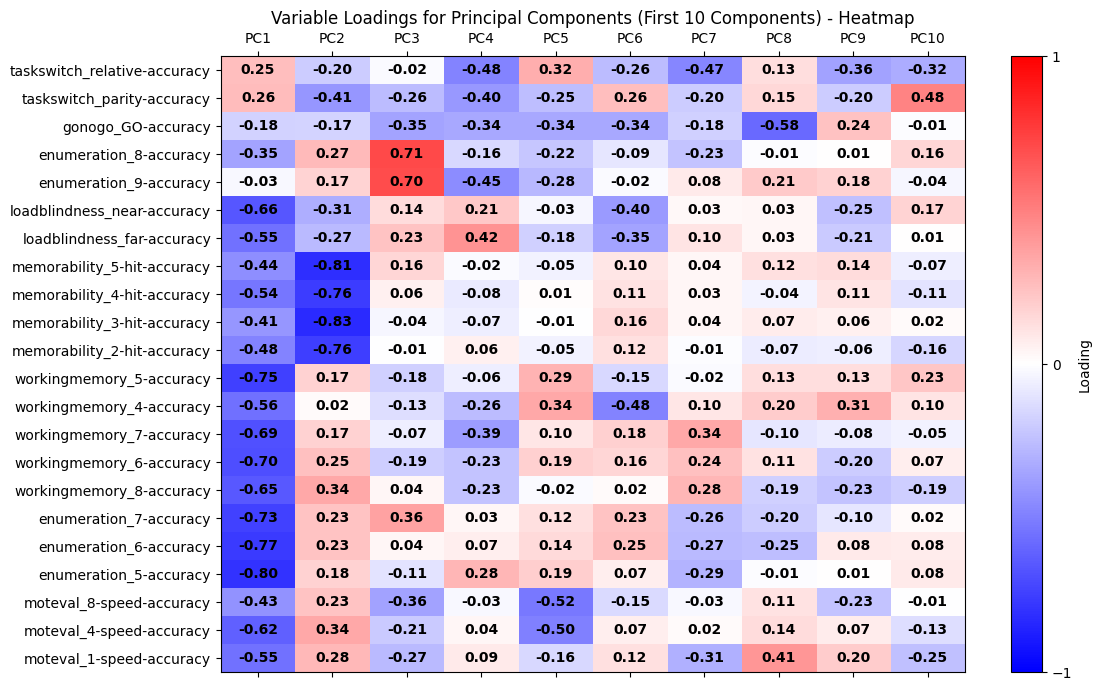

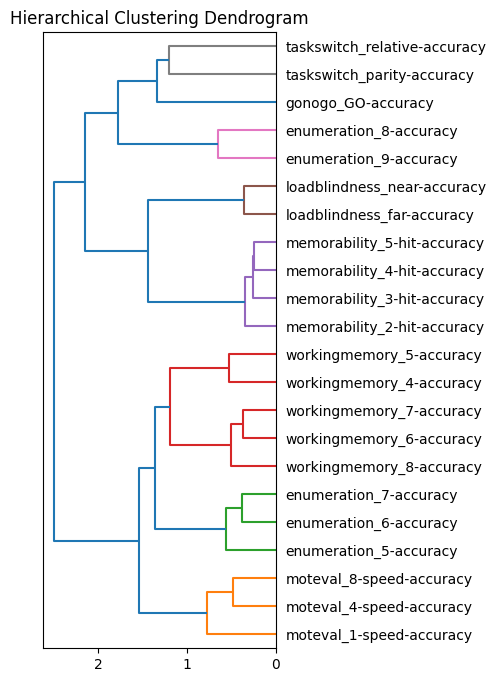

In [152]:
# Get a list of columns with at least one NaN value and the count of NaN values in each column
values_to_keep = ["v0_prolific", "v0_ubx"]
# Filter the DataFrame to keep only rows with "study" values in the list
df_v0 = df[df['study'].isin(values_to_keep)]
df_v0 = df_v0[kept_columns+tasks]
#df_v3_pre = df_v3[df_v3['task_status']=="PRE_TEST"]
run_PCA(df_v0, tasks)

/var/folders/m9/p4hnlvpx2vb5yr2f8kxl9sl40000gp/T/ipykernel_95705/349014493.py:39: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[numeric_columns] = data[numeric_columns].fillna(data[numeric_columns].mean())


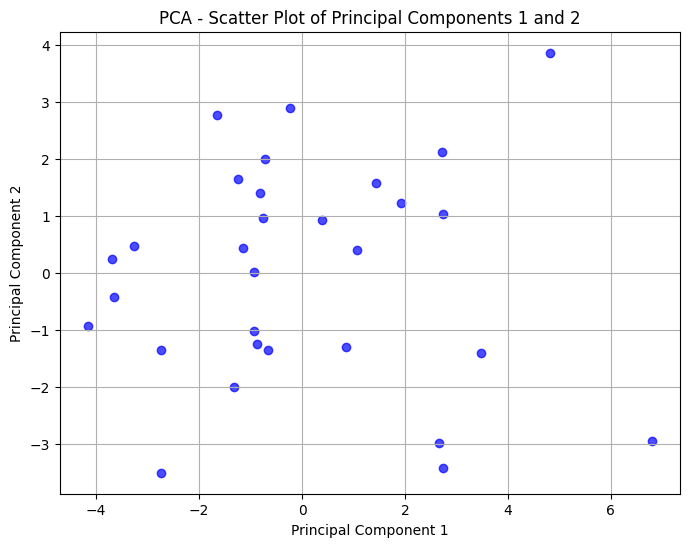

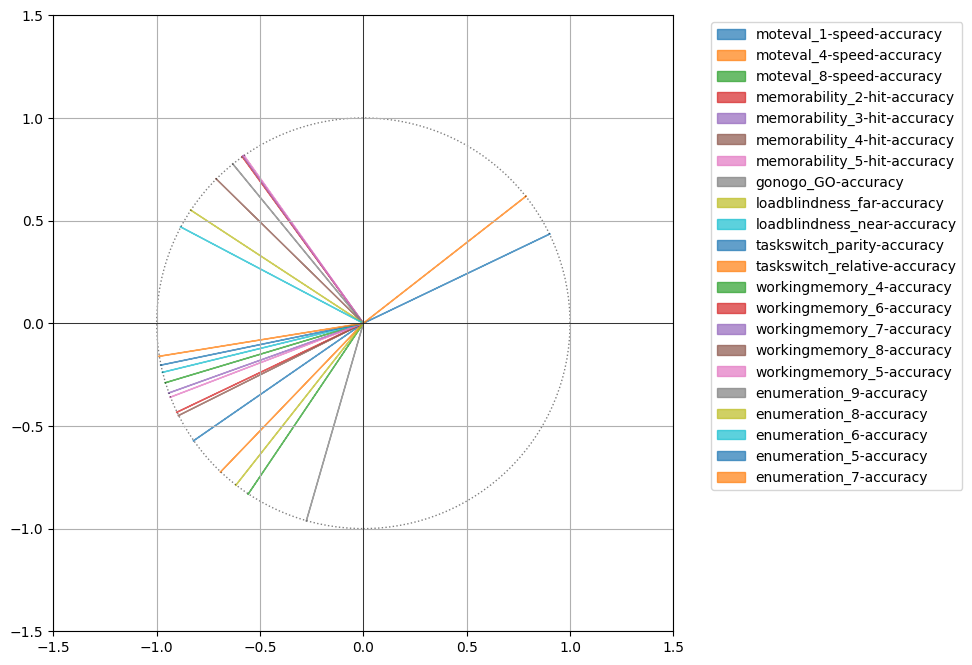

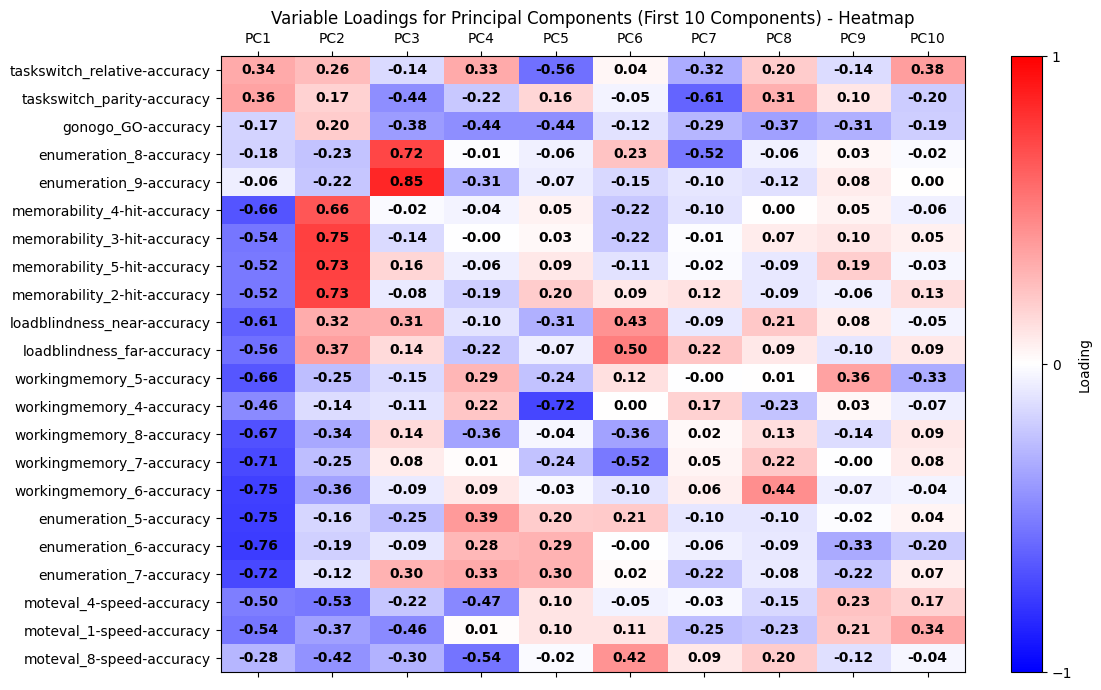

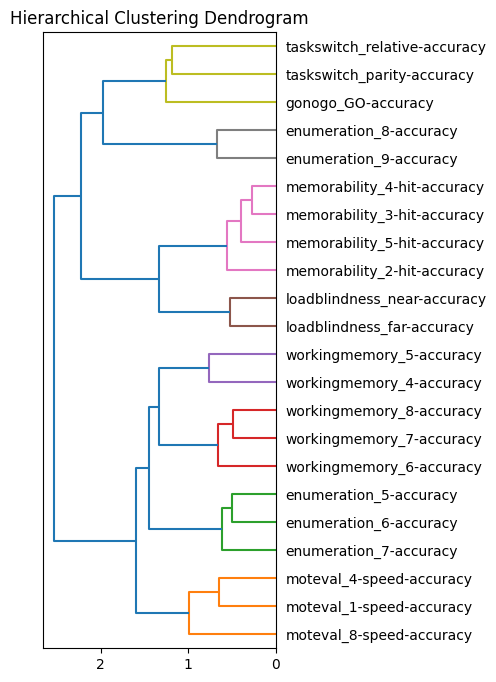

In [153]:
# Get a list of columns with at least one NaN value and the count of NaN values in each column
values_to_keep = ["v0_prolific", "v0_ubx"]
# Filter the DataFrame to keep only rows with "study" values in the list
df_v0 = df[df['study'].isin(values_to_keep)]
df_v0 = df_v0[kept_columns+tasks]
df_v0_pre = df_v0[df_v0['task_status']=="PRE_TEST"]
run_PCA(df_v0_pre, tasks)